# 21 — Week 6: data fraction and qubit count (validation), three main figures

Needs notebooks 17–19 (main hybrid QNN in `reports/week5/qnn_val.json`, QRC settings in `reports/week5/qrc_val.json`).
Code: `src/models/week6.py`. Validation only; the test split is opened once in notebook 23.

**Data fraction** 1%, 5%, 20% (+ the 100% runs that already exist): the most recent contiguous block of train origins
(provisional design; validation unchanged). Models: main hybrid QNN, its MLP control, QRC and its random-feature
control, LightGBM (univariate arm, tuned parameters, rounds by early stopping on validation, rerun at 100% with the same
rule), PatchTST and the univariate GRU (`gru_uni`, the univariate recurrent reference instead of the plan's LSTM).
Networks keep a fixed number of optimiser steps per epoch (`ceil(N_full / 512)`), so a small fraction is not also a
smaller optimisation budget. Three seeds everywhere (QRC: three random reservoirs).

**Qubit count** 2, 4, 6, 8 at 100% data: hybrid QNN (main layers / re-uploading), its entanglement ablation and its
matched MLP control; QRC, QRC without entanglement and the size-matched random-feature control (input scale chosen at 8
qubits in notebook 19, reused for all qubit counts: provisional). Runs at 4 qubits (hybrid) and 8 qubits (QRC) are
reused.

Everything is resumable (finished runs are skipped) and logged to W&B and `reports/week5/quantum_variants_log.csv`.
The 8-qubit hybrid runs are the slowest part (cell 5 prints an estimate); they can run overnight.

In [1]:
# Cell 1: setup (reads the decisions of notebooks 17-19)
import sys, json, time, math, shutil, warnings, traceback, logging
from pathlib import Path
import numpy as np
import polars as pl
import torch
import yaml
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
for name in ("pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"):
    logging.getLogger(name).setLevel(logging.ERROR)
from models import rnn as R
from models import quantum as Q
from models import qrc as QR
from models import week6 as W

REP5, REP = ROOT / "reports" / "week5", ROOT / "reports" / "week6"
FIG = ROOT / "reports" / "figures" / "week6"
REP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
for f in ("qnn_smoke.json", "qnn_val.json", "qrc_val.json"):
    assert (REP5 / f).exists(), f"missing reports/week5/{f}: run notebooks 17-19 first"
smoke = json.loads((REP5 / "qnn_smoke.json").read_text())
qv = json.loads((REP5 / "qnn_val.json").read_text())
qr = json.loads((REP5 / "qrc_val.json").read_text())
MAIN = qv["main_hybrid"]
QNN_GROUP = qv.get("group", "week5_qnn")
PROTOCOL = {**smoke["protocol"], "backend": smoke["timing"]["backend"], "epochs": int(qv.get("epoch_cap", 30))}
QRC_GROUP, QRC_N, QRC_DEPTH = "week5_qrc", int(qr["n_qubits"]), int(qr["depth"])
BEST_SCALE = {k: float(v) for k, v in qr["best_scale"].items()}
NF_CFG = yaml.safe_load((ROOT / "experiments" / "week4_nf" / "patchtst_s0" / "config.yaml").read_text())
DEV_NF = "mps" if torch.backends.mps.is_available() else "cpu"
FR_GROUP = "week6_fraction"
FRACTIONS = (0.01, 0.05, 0.20)
SEEDS = [0, 1, 2]
QUBITS = (2, 4, 6, 8)
DATA_CFG = {"scaling": "local", "calendar": False, "covariates": False}
HQ = Q.variant_name(MAIN)
CT = Q.variant_name({**MAIN, "middle": "mlp"})
QRC_NAME = {k: QR.variant_name(k, QRC_N, QRC_DEPTH) for k in ("qrc", "qrc_noent", "rf", "raw")}
SUMMARY = {"main_hybrid": MAIN, "qnn_group": QNN_GROUP, "qrc_best_scale": BEST_SCALE, "fractions": FRACTIONS,
           "qubits": QUBITS}
print(f"main hybrid {HQ} (control {CT}) in group {QNN_GROUP} | epoch cap {PROTOCOL['epochs']} | QRC n={QRC_N}, "
      f"depth {QRC_DEPTH}, scales {({k: round(v, 3) for k, v in BEST_SCALE.items()})} | PatchTST/GRU device {DEV_NF}")

main hybrid hqnn_noreup_q4_l2 (control ctrl_mlp_q4_l2) in group week5_qnn | epoch cap 30 | QRC n=8, depth 4, scales {'qrc': 0.098, 'qrc_noent': 0.196, 'rf': 0.098, 'raw': 1.571} | PatchTST/GRU device mps


In [2]:
# Cell 2: DRY RUN on synthetic data of every runner used here (tiny budgets; deleted afterwards)

def synth(n=30000, seed=0):
    rng = np.random.default_rng(seed)
    t = np.arange(n)
    x = np.zeros(n)
    e = rng.normal(0, 0.4, n)
    for i in range(1, n):
        x[i] = 0.9 * x[i - 1] + e[i]
    P = 30 + np.cumsum(rng.normal(0, 0.01, n)) + x - 0.3 * (t % 5 == 0)
    valid = np.ones(n, bool)
    for g0 in rng.choice(np.arange(500, n - 500), 6, replace=False):
        valid[g0:g0 + 150] = False
    i_tr, i_va = int(0.7 * n), int(0.85 * n)
    split = np.where(t < i_tr, "train", np.where(t < i_va, "val", "test"))
    c = np.concatenate([[0], np.cumsum(~valid)])
    win_ok = np.zeros(n, bool)
    win_ok[R.INPUT_LEN - 1:] = (c[R.INPUT_LEN:] - c[:n - R.INPUT_LEN + 1]) == 0
    Pv = np.where(valid, P, np.nan)
    L24 = pl.Series(Pv).fill_nan(None).rolling_mean(1440, min_samples=720).to_numpy()
    cols = {"minute_epoch": t * 60, "P_kW": Pv, "valid": valid, "split": split, "mod5": (t % 5).astype(np.int64),
            "hour_sin": np.sin(2 * np.pi * (t // 60 % 24) / 24), "hour_cos": np.cos(2 * np.pi * (t // 60 % 24) / 24),
            "L24_kW": L24}
    thr = {}
    for h in R.HORIZONS:
        ok = win_ok.copy()
        ok[n - h:] = False
        ok[:n - h] &= valid[h:]
        sp = np.full(n, None, dtype=object)
        tt = np.arange(n - h)
        sp[:n - h] = np.where(tt + h < i_tr, "train", np.where((tt >= i_tr) & (tt + h < i_va), "val",
                              np.where(tt >= i_va, "test", None)))
        ok &= sp != None  # noqa: E711
        rel = np.full(n, np.nan)
        rel[:n - h] = np.abs(P[h:] - P[:n - h]) / L24[:n - h]
        trm = ok & (sp == "train") & np.isfinite(rel)
        thr[str(h)] = {"rel_p95": float(np.quantile(rel[trm], 0.95))}
        ramp = np.where(ok & np.isfinite(rel), (rel > thr[str(h)]["rel_p95"]).astype(float), np.nan)
        cols[f"ok_h{h}"], cols[f"split_h{h}"], cols[f"ramp_h{h}"] = ok, sp.tolist(), ramp
    df = pl.DataFrame(cols).with_columns(pl.col("P_kW").fill_nan(None), pl.col("L24_kW").fill_nan(None))
    return df, {"thresholds": thr}


DRY = "_dryrun_week6"
sm, smeta = synth(n=30000)
COV = ["util_gpu_mean", "util_mem_mean", "temp_gpu_mean", "temp_mem_mean", "mem_used_sum", "mem_free_sum",
       "n_gpu_equiv", "gpus_alloc", "active_gpu_jobs", "active_jobs", "queued_gpu_jobs", "queued_jobs"]
sm = sm.with_columns([pl.lit(0.0).alias(f"d{k}_{c}") for c in COV for k in (1, 5)] +
                     [pl.lit(100.0).alias("gpus_alloc"), pl.lit(100.0).alias("n_gpu_equiv")])
sdata = R.Data(sm, DATA_CFG)
quiet = lambda s: None
dry_ok = True
try:
    tiny = {**PROTOCOL, "epochs": 1, "device": "cpu"}
    for kind, extra in (("hqnn", MAIN), ("ctrl_mlp", MAIN), ("gru_uni", {}), ("patchtst", {})):
        r = W.run_network_fraction(ROOT, sm, smeta, sdata, kind, {**tiny, **extra}, 0.05, 0, DRY, "disabled", quiet, kind)
        dry_ok &= all(np.isfinite(x["MAE"]) for x in r["val"])
    r = W.run_lightgbm_fraction(ROOT, sm, smeta, sdata, 0.05, 0, DRY, "disabled", quiet, max_rounds=50)
    dry_ok &= all(np.isfinite(x["MAE"]) for x in r["val"])
    sU = QR.minute_inputs(sdata, sm, 4)
    r = W.run_qrc_fraction(ROOT, sm, smeta, sdata, sU, "qrc", math.pi / 4, 0, 0.05, DRY, 4, "disabled", quiet)
    dry_ok &= all(np.isfinite(x["MAE"]) for x in r["val"])
    r = Q.run_and_score(ROOT, sm, smeta, sdata, {**tiny, **MAIN, "n_qubits": 2, "seed": 0}, DRY, "disabled", quiet)
    dry_ok &= all(np.isfinite(x["MAE"]) for x in r["val"])
    print("runners: network fraction (hybrid, MLP, GRU, PatchTST), LightGBM fraction, QRC fraction, qubit sweep: all finite")
except Exception:
    dry_ok = False
    traceback.print_exc()
finally:
    shutil.rmtree(ROOT / "experiments" / DRY, ignore_errors=True)
    shutil.rmtree(ROOT / "experiments" / "runs" / DRY, ignore_errors=True)
    for f in (ROOT / "experiments" / "_cache_qrc").glob(f"*_rows{sm.height}.npy"):
        f.unlink()
    log_p = REP5 / "quantum_variants_log.csv"
    if log_p.exists():
        lg = pl.read_csv(log_p, infer_schema_length=0)
        (lg.filter(pl.col("group") != DRY) if "group" in lg.columns else lg).write_csv(log_p)
print("DRY RUN PASSED" if dry_ok else "DRY RUN FAILED: send this output")

2026-10-11 22:29:53,291	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-11 22:29:53,908	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
Seed set to 0


runners: network fraction (hybrid, MLP, GRU, PatchTST), LightGBM fraction, QRC fraction, qubit sweep: all finite
DRY RUN PASSED


In [3]:
# Cell 3: real data; size of each fraction
assert dry_ok, "run cell 2 first"
md = pl.read_parquet(ROOT / PROTOCOL["dataset"])
meta = json.loads((ROOT / PROTOCOL["dataset_meta"]).read_text())
data = R.Data(md, DATA_CFG)
tr_all = data.origins("train")
rows = []
for f in FRACTIONS + (1.0,):
    cut = W.fraction_cutoff(data, f)
    rows.append({"fraction": f, "train_origins": int((tr_all >= cut).sum()), "first_origin": str(md["minute_local"][cut]),
                 "days_covered": round((int(tr_all[-1]) - cut) / 1440, 1)})
fr_tab = pl.DataFrame(rows)
print(fr_tab)
SUMMARY["fraction_sizes"] = fr_tab.to_dicts()

shape: (4, 4)
┌──────────┬───────────────┬─────────────────────┬──────────────┐
│ fraction ┆ train_origins ┆ first_origin        ┆ days_covered │
│ ---      ┆ ---           ┆ ---                 ┆ ---          │
│ f64      ┆ i64           ┆ str                 ┆ f64          │
╞══════════╪═══════════════╪═════════════════════╪══════════════╡
│ 0.01     ┆ 1967          ┆ 2021-07-28 08:00:00 ┆ 1.4          │
│ 0.05     ┆ 9835          ┆ 2021-07-22 20:52:00 ┆ 6.8          │
│ 0.2      ┆ 39340         ┆ 2021-06-30 07:07:00 ┆ 29.4         │
│ 1.0      ┆ 196700        ┆ 2021-03-04 00:59:00 ┆ 147.7        │
└──────────┴───────────────┴─────────────────────┴──────────────┘


In [4]:
# Cell 4: DATA FRACTION runs (1%, 5%, 20%; 3 seeds). Resumable. Order: cheap to expensive.
# Rough time: LightGBM ~5 min, QRC ~5 min (+ reservoir cache), hybrid + MLP ~30 min, GRU + PatchTST ~1.5-2 h.
T = time.time()
U = QR.minute_inputs(data, md, QRC_N)
CACHE = ROOT / "experiments" / "_cache_qrc"
def safe(fn, *a, **k):
    try:
        return fn(*a, **k)
    except Exception:
        print(f"!!! failed: {fn.__name__} {a[4:8]}")
        traceback.print_exc(limit=4)
for seed in SEEDS:
    for f in FRACTIONS + (1.0,):
        safe(W.run_lightgbm_fraction, ROOT, md, meta, data, f, seed, FR_GROUP)
for seed in SEEDS:
    for f in FRACTIONS:
        for k in ("qrc", "rf"):
            safe(W.run_qrc_fraction, ROOT, md, meta, data, U, k, BEST_SCALE[k], seed, f, FR_GROUP, QRC_DEPTH)
for seed in SEEDS:
    for f in FRACTIONS:
        safe(W.run_network_fraction, ROOT, md, meta, data, "hqnn", {**PROTOCOL, **MAIN, "device": "cpu"}, f, seed,
             FR_GROUP, "auto", print, HQ)
        safe(W.run_network_fraction, ROOT, md, meta, data, "ctrl_mlp", {**PROTOCOL, **MAIN, "device": "cpu"}, f, seed,
             FR_GROUP, "auto", print, CT)
for seed in SEEDS:
    for f in FRACTIONS:
        for k in ("gru_uni", "patchtst"):
            safe(W.run_network_fraction, ROOT, md, meta, data, k, {**NF_CFG, "device": DEV_NF}, f, seed, FR_GROUP,
                 "auto", print, k)
print(f"\ndata-fraction runs handled in {(time.time() - T) / 60:.1f} min")

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/aryaneuse/.netrc.


[22:30:09] lightgbm_f001_s0: rounds {1: 47, 5: 32, 15: 6} | skill +0.067 / +0.029 / +0.005
[22:30:19] lightgbm_f005_s0: rounds {1: 47, 5: 173, 15: 29} | skill +0.086 / +0.055 / +0.026
[22:30:34] lightgbm_f020_s0: rounds {1: 141, 5: 210, 15: 35} | skill +0.119 / +0.079 / +0.047
[22:31:20] lightgbm_f100_s0: rounds {1: 692, 5: 646, 15: 90} | skill +0.131 / +0.085 / +0.065
[22:31:30] lightgbm_f001_s1: rounds {1: 51, 5: 29, 15: 4} | skill +0.067 / +0.029 / +0.004
[22:31:42] lightgbm_f005_s1: rounds {1: 53, 5: 188, 15: 27} | skill +0.087 / +0.054 / +0.026
[22:32:00] lightgbm_f020_s1: rounds {1: 123, 5: 211, 15: 41} | skill +0.120 / +0.079 / +0.048
[22:32:49] lightgbm_f100_s1: rounds {1: 900, 5: 677, 15: 92} | skill +0.131 / +0.085 / +0.064
[22:33:00] lightgbm_f001_s2: rounds {1: 44, 5: 34, 15: 6} | skill +0.070 / +0.032 / +0.006
[22:33:14] lightgbm_f005_s2: rounds {1: 64, 5: 166, 15: 35} | skill +0.092 / +0.056 / +0.027
[22:33:28] lightgbm_f020_s2: rounds {1: 133, 5: 215, 15: 38} | skill +0.

Seed set to 0


[22:56:24] gru_uni_f001_s0: params 38,019 | best epoch 1/4 | 135 s | skill -0.026 / -0.087 / -0.086
[22:56:24] patchtst_f001_s0: 1,967 train origins
[23:19:46] patchtst_f001_s0: params 75,215 | best epoch 19/22 | 1396 s | skill -0.085 / -0.162 / -0.131
[23:19:47] gru_uni_f005_s0: 9,835 train origins


Seed set to 0


...

[23:42:50] gru_uni_f001_s2: params 38,019 | best epoch 1/4 | 144 s | skill -0.024 / -0.072 / -0.088
[23:42:50] patchtst_f001_s2: 1,967 train origins
[23:45:14] patchtst_f001_s2: params 75,215 | best epoch 8/11 | 138 s | skill -0.131 / -0.180 / -0.143
[23:45:14] gru_uni_f005_s2: 9,835 train origins


Seed set to 2


[23:47:45] gru_uni_f005_s2: params 38,019 | best epoch 1/4 | 144 s | skill -0.024 / +0.057 / +0.037
[23:47:45] patchtst_f005_s2: 9,835 train origins
[23:48:41] patchtst_f005_s2: params 75,215 | best epoch 1/4 | 51 s | skill +0.071 / +0.051 / +0.021
[23:48:41] gru_uni_f020_s2: 39,340 train origins


Seed set to 2


[23:51:11] gru_uni_f020_s2: params 38,019 | best epoch 1/4 | 144 s | skill +0.018 / +0.066 / +0.054
[23:51:11] patchtst_f020_s2: 39,340 train origins
[23:52:21] patchtst_f020_s2: params 75,215 | best epoch 2/5 | 63 s | skill +0.083 / +0.070 / +0.047

data-fraction runs handled in 82.4 min


In [5]:
# Cell 5: QUBIT SWEEP at 100% data (3 seeds). QRC first (fast), then the hybrid family by increasing qubit count.
tim = pl.read_csv(REP5 / "qnn_timing.csv")
L = int(MAIN["n_layers"])
est = tim.filter(pl.col("variant").str.starts_with("hqnn") & pl.col("variant").str.ends_with(f"_l{L}")
                 & (pl.col("backend") == "default.qubit"))
print("estimated minutes per epoch (full train) of the hybrid QNN by qubits:",
      dict(zip(est["variant"].to_list(), est["est_epoch_min_full"].to_list())),
      "| x ~15 epochs x 3 seeds x 2 (with / without entanglement)")
T = time.time()
for n in QUBITS:
    Un = QR.minute_inputs(data, md, n)
    for seed in SEEDS:
        for k in ("qrc", "qrc_noent", "rf", "raw"):
            if k == "raw" and seed > 0:
                continue
            safe(QR.run_and_score, ROOT, md, meta, data, Un, k, BEST_SCALE[k], seed, QRC_GROUP, depth=QRC_DEPTH)
print(f"QRC sweep handled in {(time.time() - T) / 60:.1f} min")
T = time.time()
for n in QUBITS:
    for seed in SEEDS:
        for v in ({"middle": "mlp"}, {"middle": "quantum"}, {"middle": "quantum", "entangle": False}):
            cfg = {**PROTOCOL, **MAIN, **v, "n_qubits": n, "seed": seed}
            safe(Q.run_and_score, ROOT, md, meta, data, cfg, QNN_GROUP)
print(f"hybrid sweep handled in {(time.time() - T) / 60:.1f} min")

estimated minutes per epoch (full train) of the hybrid QNN by qubits: {'hqnn_q2_l2': 0.04, 'hqnn_q4_l2': 0.09, 'hqnn_q6_l2': 0.24, 'hqnn_q8_l2': 1.51} | x ~15 epochs x 3 seeds x 2 (with / without entanglement)
[23:52:21] qrc_q2_d4_a0p098_s0: reservoir + readout
[23:52:28] qrc_q2_d4_a0p098_s0: features 32 | readout params 99 | reservoir 1 s | val MAE 0.2719 / 0.4134 / 0.5874 kW | skill +0.051 / +0.039 / +0.029
[23:52:28] qrc_noent_q2_d4_a0p196_s0: reservoir + readout
[23:52:34] qrc_noent_q2_d4_a0p196_s0: features 32 | readout params 99 | reservoir 0 s | val MAE 0.2720 / 0.4137 / 0.5884 kW | skill +0.051 / +0.038 / +0.027
[23:52:34] ctrl_rf_q2_f8_a0p098_s0: reservoir + readout
[23:52:40] ctrl_rf_q2_f8_a0p098_s0: features 32 | readout params 99 | reservoir 0 s | val MAE 0.2706 / 0.4117 / 0.5859 kW | skill +0.056 / +0.043 / +0.031
[23:52:40] ctrl_raw_q2_s0: reservoir + readout
[23:52:46] ctrl_raw_q2_s0: features 8 | readout params 27 | reservoir 0 s | val MAE 0.2739 / 0.4165 / 0.5921 kW | 

In [6]:
# Cell 6: tables (mean +- sd over seeds): data fraction and qubit count
def load(group, run):
    p = ROOT / "experiments" / group / run / "metrics.json"
    return json.loads(p.read_text()) if p.exists() else None

def rows_of(res, **tags):
    if res is None:
        return []
    n_par = res["info"].get("n_params")
    return [{**tags, "h": v["h"], "MAE": v["MAE"], "skill": v["skill_MAE"], "MAE_ramp": v.get("MAE_ramp"),
             "n_params": n_par} for v in res["val"]]

FR_MODELS = {"hybrid QNN": HQ, "MLP control": CT, "QRC": "qrc", "RF control": "rf", "LightGBM": "lightgbm",
             "PatchTST": "patchtst", "GRU (univariate)": "gru_uni"}
rows = []
for label, key in FR_MODELS.items():
    for f in FRACTIONS + (1.0,):
        for seed in SEEDS:
            if f < 1.0:
                run = (f"{QRC_NAME[key]}_{W.frac_tag(f)}_s{seed}" if key in ("qrc", "rf") else f"{key}_{W.frac_tag(f)}_s{seed}")
                res = load(FR_GROUP, run)
            elif key == "lightgbm":
                res = load(FR_GROUP, f"lightgbm_f100_s{seed}")
            elif key in ("qrc", "rf"):
                res = load(QRC_GROUP, f"{QRC_NAME[key]}_{QR.scale_tag(BEST_SCALE[key])}_s{seed}")
            elif key in ("patchtst", "gru_uni"):
                res = load("week4_nf", f"{key}_s{seed}")
            else:
                res = load(QNN_GROUP, f"{key}_s{seed}")
            rows += rows_of(res, model=label, fraction=f, seed=seed)
fr = pl.DataFrame(rows)
fr_s = (fr.group_by("model", "fraction", "h").agg(pl.len().alias("n_seeds"), pl.col("skill").mean().alias("skill_mean"),
        pl.col("skill").std().alias("skill_sd"), pl.col("MAE").mean().alias("MAE_mean"), pl.col("MAE_ramp").mean())
        .sort("h", "model", "fraction"))
fr_s.write_csv(REP / "data_fraction_val.csv")
pl.Config.set_tbl_rows(120); pl.Config.set_tbl_width_chars(220)
print(fr_s.pivot(on="fraction", index=["h", "model"], values="skill_mean").sort("h", "model")
          .with_columns(pl.exclude("h", "model").round(3)))
print("missing combinations:", fr_s.filter(pl.col("n_seeds") < 3).select("model", "fraction", "h", "n_seeds").to_dicts() or "none")

rows = []
for n in QUBITS:
    for seed in SEEDS:
        for label, cfgv in (("hybrid QNN", {}), ("hybrid, no entanglement", {"entangle": False}), ("MLP control", {"middle": "mlp"})):
            nm = Q.variant_name({**MAIN, **cfgv, "n_qubits": n})
            rows += rows_of(load(QNN_GROUP, f"{nm}_s{seed}"), model=label, n_qubits=n, seed=seed)
        for label, k in (("QRC", "qrc"), ("QRC, no entanglement", "qrc_noent"), ("RF control", "rf"), ("raw control", "raw")):
            if k == "raw" and seed > 0:
                continue
            base = QR.variant_name(k, n, QRC_DEPTH)
            run = f"{base}_s0" if k == "raw" else f"{base}_{QR.scale_tag(BEST_SCALE[k])}_s{seed}"
            rows += rows_of(load(QRC_GROUP, run), model=label, n_qubits=n, seed=seed)
qb = pl.DataFrame(rows)
qb_s = (qb.group_by("model", "n_qubits", "h").agg(pl.len().alias("n_seeds"), pl.col("skill").mean().alias("skill_mean"),
        pl.col("skill").std().alias("skill_sd"), pl.col("n_params").first()).sort("h", "model", "n_qubits"))
qb_s.write_csv(REP / "qubit_sweep_val.csv")
print(qb_s.pivot(on="n_qubits", index=["h", "model"], values="skill_mean").sort("h", "model")
          .with_columns(pl.exclude("h", "model").round(3)))
SUMMARY["data_fraction"] = fr_s.to_dicts()
SUMMARY["qubit_sweep"] = qb_s.to_dicts()

shape: (21, 6)
┌─────┬──────────────────┬────────┬────────┬───────┬───────┐
│ h   ┆ model            ┆ 0.01   ┆ 0.05   ┆ 0.2   ┆ 1.0   │
│ --- ┆ ---              ┆ ---    ┆ ---    ┆ ---   ┆ ---   │
│ i64 ┆ str              ┆ f64    ┆ f64    ┆ f64   ┆ f64   │
╞═════╪══════════════════╪════════╪════════╪═══════╪═══════╡
│ 1   ┆ GRU (univariate) ┆ -0.025 ┆ -0.002 ┆ 0.02  ┆ 0.058 │
│ 1   ┆ LightGBM         ┆ 0.068  ┆ 0.088  ┆ 0.12  ┆ 0.131 │
│ 1   ┆ MLP control      ┆ -0.035 ┆ 0.051  ┆ 0.072 ┆ 0.056 │
│ 1   ┆ PatchTST         ┆ -0.107 ┆ 0.061  ┆ 0.082 ┆ 0.112 │
│ 1   ┆ QRC              ┆ 0.035  ┆ 0.039  ┆ 0.052 ┆ 0.075 │
│ 1   ┆ RF control       ┆ 0.038  ┆ 0.037  ┆ 0.056 ┆ 0.077 │
│ 1   ┆ hybrid QNN       ┆ -0.027 ┆ 0.06   ┆ 0.063 ┆ 0.074 │
│ 5   ┆ GRU (univariate) ┆ -0.079 ┆ 0.051  ┆ 0.064 ┆ 0.066 │
│ 5   ┆ LightGBM         ┆ 0.03   ┆ 0.055  ┆ 0.078 ┆ 0.085 │
│ 5   ┆ MLP control      ┆ -0.001 ┆ 0.031  ┆ 0.041 ┆ 0.053 │
│ 5   ┆ PatchTST         ┆ -0.163 ┆ 0.044  ┆ 0.061 ┆ 0.072 │
│ 5   ┆ Q

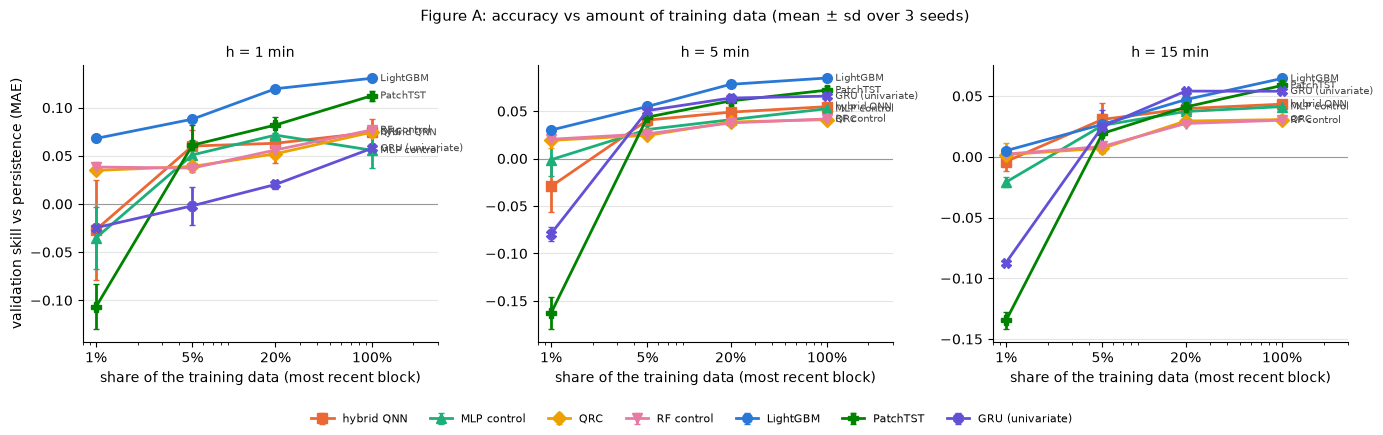

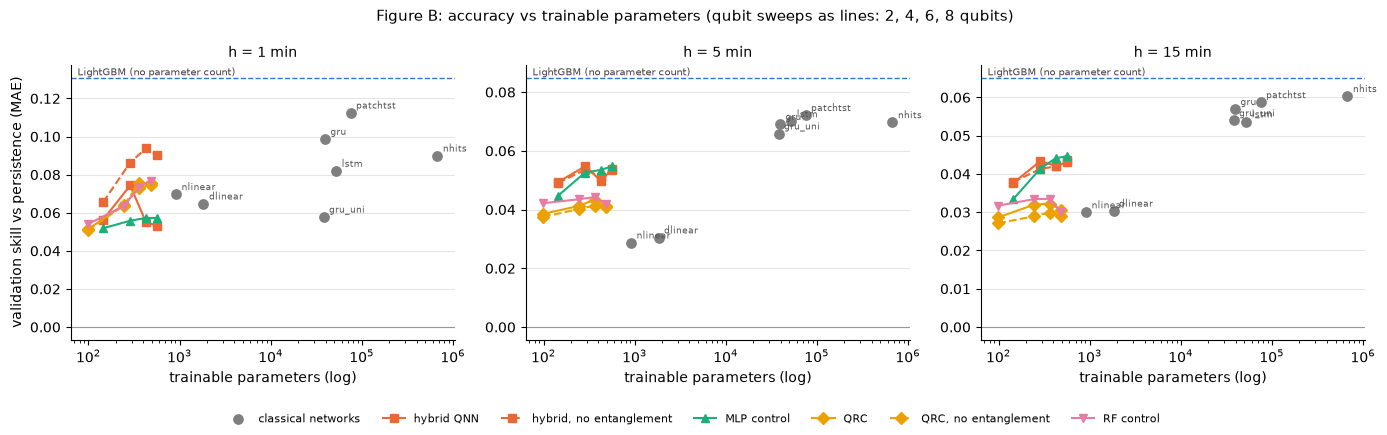

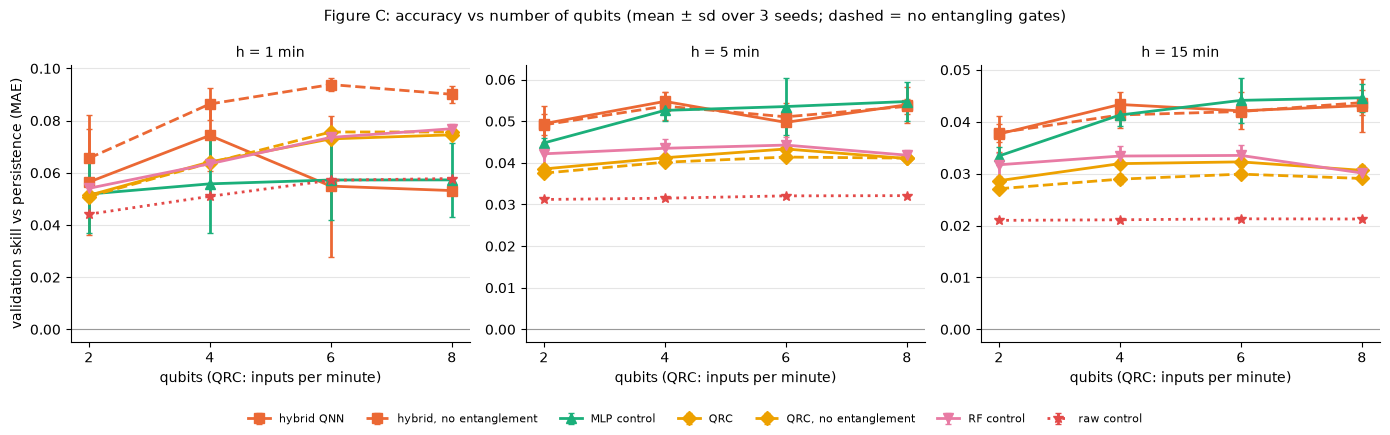

In [7]:
# Cell 7: the three main figures of Sprint 3 (validation): skill vs data fraction, vs trainable parameters, vs qubits.
# Fixed colour per model (categorical slots in fixed order), plus marker and line style, so identity is not colour-only.
STYLE = {"LightGBM": ("#2a78d6", "o", "-"), "hybrid QNN": ("#eb6834", "s", "-"), "MLP control": ("#1baf7a", "^", "-"),
         "QRC": ("#eda100", "D", "-"), "RF control": ("#e87ba4", "v", "-"), "PatchTST": ("#008300", "P", "-"),
         "GRU (univariate)": ("#6250d6", "X", "-"), "hybrid, no entanglement": ("#eb6834", "s", "--"),
         "QRC, no entanglement": ("#eda100", "D", "--"), "raw control": ("#e34948", "*", ":")}

def style_ax(ax):
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    ax.axhline(0, color="#999999", lw=0.8)

# Figure 1: skill vs data fraction
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, h in zip(axes, R.HORIZONS):
    for m in FR_MODELS:
        s = fr_s.filter((pl.col("model") == m) & (pl.col("h") == h)).sort("fraction")
        if not s.height:
            continue
        c, mk, ls = STYLE[m]
        x = (s["fraction"] * 100).to_numpy()
        ax.errorbar(x, s["skill_mean"], yerr=s["skill_sd"].fill_null(0), color=c, marker=mk, ls=ls, lw=2, ms=7,
                    capsize=2, label=m)
        ax.annotate(m, (x[-1], s["skill_mean"][-1]), xytext=(6, 0), textcoords="offset points", va="center",
                    fontsize=7, color="#444444")
    ax.set_xscale("log"); ax.set_xticks([1, 5, 20, 100]); ax.set_xticklabels(["1%", "5%", "20%", "100%"])
    ax.set_xlim(0.8, 300)
    ax.set_title(f"h = {h} min", fontsize=10); ax.set_xlabel("share of the training data (most recent block)")
    style_ax(ax)
axes[0].set_ylabel("validation skill vs persistence (MAE)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, fontsize=8, loc="lower center", ncol=7)
fig.suptitle("Figure A: accuracy vs amount of training data (mean ± sd over 3 seeds)", fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG / "A_skill_vs_data_fraction.png", dpi=150); plt.show()

# Figure 2: skill vs trainable parameters (all validation models with a parameter count, incl. the qubit sweep)
b5 = REP5 / "benchmark_val_week5.csv"
bench = pl.read_csv(b5) if b5.exists() else None
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
for ax, h in zip(axes, R.HORIZONS):
    if bench is not None:
        cls = bench.filter((pl.col("h") == h) & (pl.col("family") == "deep") & pl.col("n_params").is_not_null())
        ax.scatter(cls["n_params"], cls["skill_MAE"], s=45, color="#7f7f7f", marker="o", label="classical networks", zorder=2)
        for r_ in cls.iter_rows(named=True):
            ax.annotate(r_["model"], (r_["n_params"], r_["skill_MAE"]), xytext=(4, 3), textcoords="offset points",
                        fontsize=6.5, color="#555555")
        lg = bench.filter((pl.col("h") == h) & (pl.col("model") == "lightgbm"))
        if lg.height:
            ax.axhline(lg["skill_MAE"][0], color="#2a78d6", lw=1, ls="--")
            ax.text(0.01, lg["skill_MAE"][0], " LightGBM (no parameter count)", transform=ax.get_yaxis_transform(),
                    va="bottom", fontsize=7, color="#444444")
    for m in ("hybrid QNN", "hybrid, no entanglement", "MLP control", "QRC", "QRC, no entanglement", "RF control"):
        s = qb_s.filter((pl.col("model") == m) & (pl.col("h") == h)).sort("n_params")
        if not s.height:
            continue
        c, mk, ls = STYLE[m]
        ax.plot(s["n_params"], s["skill_mean"], color=c, marker=mk, ls=ls, lw=1.5, ms=6, label=m, zorder=3)
    ax.set_xscale("log"); ax.set_title(f"h = {h} min", fontsize=10); ax.set_xlabel("trainable parameters (log)")
    style_ax(ax)
axes[0].set_ylabel("validation skill vs persistence (MAE)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, fontsize=8, loc="lower center", ncol=7)
fig.suptitle("Figure B: accuracy vs trainable parameters (qubit sweeps as lines: 2, 4, 6, 8 qubits)", fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG / "B_skill_vs_params.png", dpi=150); plt.show()

# Figure 3: skill vs number of qubits
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))
QB_MODELS = ["hybrid QNN", "hybrid, no entanglement", "MLP control", "QRC", "QRC, no entanglement", "RF control", "raw control"]
for ax, h in zip(axes, R.HORIZONS):
    for m in QB_MODELS:
        s = qb_s.filter((pl.col("model") == m) & (pl.col("h") == h)).sort("n_qubits")
        if not s.height:
            continue
        c, mk, ls = STYLE[m]
        ax.errorbar(s["n_qubits"], s["skill_mean"], yerr=s["skill_sd"].fill_null(0), color=c, marker=mk, ls=ls, lw=2,
                    ms=7, capsize=2, label=m)
    ax.set_xticks(list(QUBITS)); ax.set_title(f"h = {h} min", fontsize=10); ax.set_xlabel("qubits (QRC: inputs per minute)")
    style_ax(ax)
axes[0].set_ylabel("validation skill vs persistence (MAE)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, fontsize=8, loc="lower center", ncol=7)
fig.suptitle("Figure C: accuracy vs number of qubits (mean ± sd over 3 seeds; dashed = no entangling gates)", fontsize=11)
fig.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG / "C_skill_vs_qubits.png", dpi=150); plt.show()

In [8]:
# Cell 8: summary
(REP / "week6_fraction_qubits.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
print("written:", sorted(p.name for p in REP.iterdir()), "| figures:", sorted(p.name for p in FIG.iterdir()))

written: ['data_fraction_val.csv', 'qubit_sweep_val.csv', 'week6_fraction_qubits.json'] | figures: ['A_skill_vs_data_fraction.png', 'B_skill_vs_params.png', 'C_skill_vs_qubits.png']


In [11]:
# Cell 9: export outputs (save the notebook first with Cmd+S, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 21_week6_fraction_qubits.ipynb

written 21_week6_fraction_qubits_outputs.md | code cells 10 | figures 3 in 21_week6_fraction_qubits_outputs_figures
